<a href="https://colab.research.google.com/github/patcharaponkaewnil90-hash/deep-learning/blob/main/ProExam01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fashion-MNIST: เปรียบเทียบ DNN, CNN และทดลองปรับปรุงโมเดล
รันเซลล์จากบนลงล่าง หรือ Restart Kernel แล้ว Run All เพื่อให้ตัวแปรตรงกันทั้งงาน

ลำดับงาน: ตรวจข้อมูล → แบ่ง Train/Validation → ฝึก DNN โมเดลเดิม และ CNN → เลือก โมเดลเดิมที่เลือก ด้วย Validation → เพิ่ม Dropout และ Early Stopping → เปรียบเทียบ → เลือกโมเดลสุดท้าย → ประเมิน Test → วิเคราะห์ภาพที่ผิด




In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

tf.keras.utils.set_random_seed(42)
EPOCHS = 10
BATCH_SIZE = 64


TensorFlow: 2.21.0
GPU: []
Seed=42, Epoch limit=10, Batch size=64


## 2. โหลดและตรวจข้อมูลดิบ



In [27]:
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Image dtype: uint8
Raw pixel range: 0 to 255
First 10 labels: [9 0 0 3 0 2 7 2 5 5]


## 3. จับคู่เลขคลาสกับชื่อเสื้อผ้าและดูภาพตัวอย่าง
ชื่อใน `class_names`


In [28]:
class_names = [
    "T-shirt/top",  # 0
    "Trouser",      # 1
    "Pullover",     # 2
    "Dress",        # 3
    "Coat",         # 4
    "Sandal",       # 5
    "Shirt",        # 6
    "Sneaker",      # 7
    "Bag",          # 8
    "Ankle boot"    # 9
]
display(pd.DataFrame({"Label": range(10), "Class": class_names}))


,Label,Class
0,0,T-shirt/top
1,1,Trouser
2,2,Pullover
3,3,Dress
4,4,Coat
5,5,Sandal
6,6,Shirt
7,7,Sneaker
8,8,Bag
9,9,Ankle boot


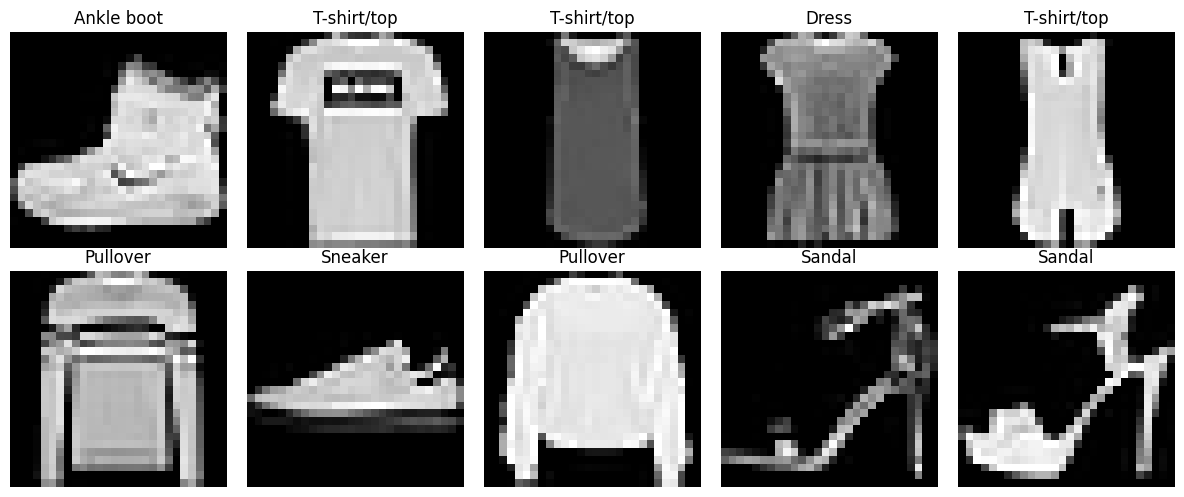

In [29]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


## 4. ปรับพิกเซลเป็นช่วง 0–1
แปลงเป็น float32 แล้วหารด้วย 255


In [30]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("Normalized pixel range:", x_train_full.min(), "to", x_train_full.max())


Minimum: 0.0
Maximum: 1.0
Normalized dtype: float32
Test range: 0.0 to 1.0


## 5. แบ่ง Validation จากชุด Training เดิม



In [31]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)


Train: (48000, 28, 28)
Validation: (12000, 28, 28)
Test: (10000, 28, 28)


,Class,Train,Validation,Test
0,T-shirt/top,4800,1200,1000
1,Trouser,4800,1200,1000
2,Pullover,4800,1200,1000
3,Dress,4800,1200,1000
4,Coat,4800,1200,1000
5,Sandal,4800,1200,1000
6,Shirt,4800,1200,1000
7,Sneaker,4800,1200,1000
8,Bag,4800,1200,1000
9,Ankle boot,4800,1200,1000


## 6. สร้าง DNN
DNN รับภาพ (28, 28) แล้ว Flatten เป็นเวกเตอร์ 784 ค่า


In [32]:
dnn_original = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="dnn_original")

dnn_original.summary()


Model: "dnn_original"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## 7. กำหนดวิธีเรียนรู้และฝึก DNN
 ใช้ sparse categorical crossentropy เพราะคำตอบเป็นเลขคลาส ไม่ใช่ one-hot


In [33]:
dnn_original.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [34]:
history_dnn_original = dnn_original.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.8113 - loss: 0.5372 - val_accuracy: 0.8520 - val_loss: 0.4159
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8596 - loss: 0.3865 - val_accuracy: 0.8673 - val_loss: 0.3723
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8746 - loss: 0.3440 - val_accuracy: 0.8702 - val_loss: 0.3550
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8817 - loss: 0.3177 - val_accuracy: 0.8716 - val_loss: 0.3430
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8903 - loss: 0.2974 - val_accuracy: 0.8759 - val_loss: 0.3343
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8955 - loss: 0.2819 - val_accuracy: 0.8730 - val_loss: 0.3413
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9004 - loss: 0.2688 - val_accuracy: 0.8739 - val_loss: 0.3524
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9036 - loss: 0.2571 - val_accuracy: 

## 8. แสดงผล DNN


In [35]:
def history_table(history):
    table = pd.DataFrame(history.history)
    table.index = np.arange(1, len(table) + 1)
    table.index.name = "Epoch"
    return table

display(history_table(history_dnn_original).round(4))


,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.8113,0.5372,0.8520,0.4159
2,0.8596,0.3865,0.8673,0.3723
3,0.8746,0.3440,0.8702,0.3550
4,0.8817,0.3177,0.8716,0.3430
5,0.8903,0.2974,0.8759,0.3343
6,0.8955,0.2819,0.8730,0.3413
7,0.9004,0.2688,0.8739,0.3524
8,0.9036,0.2571,0.8773,0.3415
9,0.9080,0.2460,0.8768,0.3480


## 9. เตรียมรูปทรงข้อมูลสำหรับ CNN
เพิ่มแกน Channel ขนาด 1 เพราะเป็นภาพสีเทา จาก (จำนวนภาพ, 28, 28) เป็น (จำนวนภาพ, 28, 28, 1) ภาพและคำตอบยังเป็นชุดเดียวกับ DNN


In [36]:
x_train_cnn = x_train[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

for name, data in [("Train CNN", x_train_cnn), ("Validation CNN", x_val_cnn), ("Test CNN", x_test_cnn)]:
    print(f"{name}: {data.shape}")


Train CNN: (48000, 28, 28, 1)
Validation CNN: (12000, 28, 28, 1)
Test CNN: (10000, 28, 28, 1)


## 10. สร้างและฝึก CNN โมเดลเดิม
Conv2D เรียนรู้ลักษณะเชิงพื้นที่ MaxPooling ลดขนาด Feature Map แล้ว Dense ใช้ลักษณะที่ได้จำแนกประเภท ใช้จำนวน Epoch และ Batch size เท่ากับ DNN


In [37]:
cnn_original = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="valid"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="valid"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="cnn_original")

cnn_original.summary()


Model: "cnn_original"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
cnn_original.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_original = cnn_original.fit(
    x_train_cnn,
    y_train,
    validation_data=(x_val_cnn, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 56ms/step - accuracy: 0.8035 - loss: 0.5465 - val_accuracy: 0.8635 - val_loss: 0.3850
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.8702 - loss: 0.3600 - val_accuracy: 0.8822 - val_loss: 0.3335
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 55ms/step - accuracy: 0.8884 - loss: 0.3102 - val_accuracy: 0.8852 - val_loss: 0.3151
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.8990 - loss: 0.2788 - val_accuracy: 0.8903 - val_loss: 0.3043
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.9073 - loss: 0.2545 - val_accuracy: 0.8932 - val_loss: 0.2959
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 56ms/step - accuracy: 0.9138 - loss: 0.2326 - val_accuracy: 0.8954 - val_loss: 0.2902
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9223 - loss: 0.2131 - val_accuracy: 0.8985 - val_loss: 0.2890
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 55ms/step - accuracy: 0.9284 - loss: 0.1958 - 

,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.8035,0.5465,0.8635,0.3850
2,0.8702,0.3600,0.8822,0.3335
3,0.8884,0.3102,0.8852,0.3151
4,0.8990,0.2788,0.8903,0.3043
5,0.9073,0.2545,0.8932,0.2959
6,0.9138,0.2326,0.8954,0.2902
7,0.9223,0.2131,0.8985,0.2890
8,0.9284,0.1958,0.9022,0.2845
9,0.9350,0.1789,0.9037,0.2812


## 11. อ่านกราฟ Accuracy และ Loss ของทั้งสองโมเดล
Accuracy สูงขึ้น = ตอบถูกมากขึ้น; Loss ต่ำลง = ความผิดพลาดตามฟังก์ชันที่ใช้ฝึกลดลง

ถ้า Training Loss ลดแต่ Validation Loss เพิ่มต่อเนื่อง เป็นสัญญาณ Overfitting ช่องว่าง Accuracy เพียงอย่างเดียวยังไม่พอสรุป ถ้าทั้งสองชุดยังดีขึ้นอาจยังฝึกต่อได้ ถ้าทั้งสองแย่และนิ่งให้ตรวจข้อมูล การฝึก และความสามารถของโมเดล


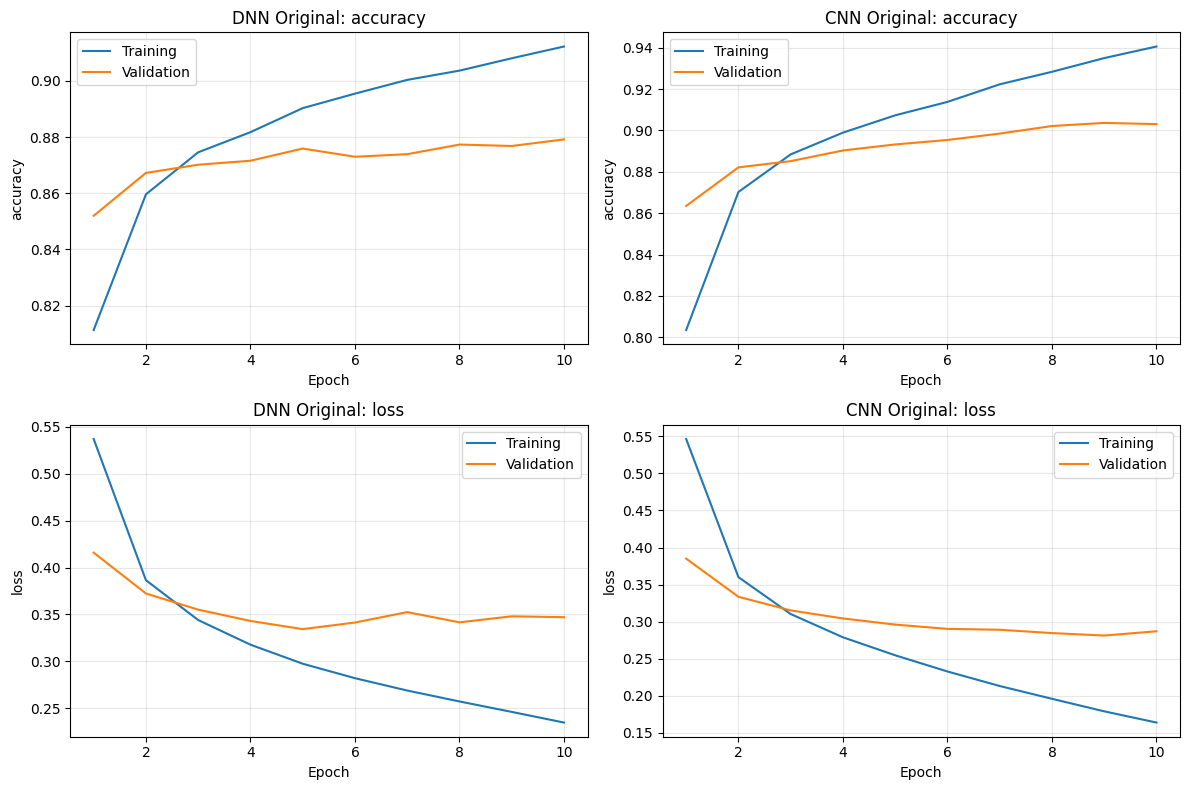

In [39]:
# กราฟ Accuracy ของโมเดลเดิมทั้งสองตัว
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, history in zip(axes, ["DNN Original", "CNN Original"],
                              [history_dnn_original, history_cnn_original]):
    ax.plot(history.history["accuracy"], label="Training")
    ax.plot(history.history["val_accuracy"], label="Validation")
    ax.set(title=name, xlabel="Epoch index (starting at 0)", ylabel="Accuracy")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 12. เลือก โมเดลเดิมที่เลือก ด้วย Validation
ประเมินน้ำหนักปัจจุบันของ DNN และ CNN แล้วแสดงคะแนนทั้งคู่ก่อนเลือก ตัวเดิมยังไม่ได้คืนค่าน้ำหนักจาก Epoch ก่อนหน้า จึงไม่ใช้ค่าสูงสุดใน History แทนน้ำหนักปัจจุบัน

โมเดลเดิมที่เลือก หมายถึงโมเดลเดิมที่ใช้เทียบ ไม่ใช่โมเดลชนิดใหม่ `history_selected_original` เก็บประวัติ ส่วน `x_*_selected` เลือกข้อมูลให้ตรงรูปทรงของโมเดล กรณีคะแนนเท่ากันกำหนดให้เลือก CNN


In [40]:
dnn_val_acc = history_dnn_original.history["val_accuracy"][-1]
cnn_val_acc = history_cnn_original.history["val_accuracy"][-1]

if cnn_val_acc >= dnn_val_acc:
    use_cnn = True
    baseline = cnn_original
    baseline_history = history_cnn_original
    baseline_name = "CNN Original"
else:
    use_cnn = False
    baseline = dnn_original
    baseline_history = history_dnn_original
    baseline_name = "DNN Original"

print("DNN Validation Accuracy:", dnn_val_acc)
print("CNN Validation Accuracy:", cnn_val_acc)
print("เลือกโมเดล:", baseline_name)


,Model,Validation Loss,Validation Accuracy (%)
0,DNN Original,0.347,87.9167
1,CNN Original,0.287,90.3083


โมเดลเดิมที่เลือกมาเปรียบเทียบ: CNN Original
Selected input shape: (48000, 28, 28, 1)
CNN minus DNN validation accuracy: +2.392 percentage points


## 13. ตั้งสมมติฐานและสร้าง โมเดลใหม่ (เพิ่ม Dropout + Early Stopping) แยกจาก โมเดลเดิมที่เลือก
เราจะทดลองสองเทคนิค โดยคงชั้นเดิมและข้อมูลเดิมไว้:

| เทคนิค | เปลี่ยนอะไร | เหตุผลที่ทดลอง |
|---|---|---|
| Dropout 0.3 | สุ่มปิดผลลัพธ์บางหน่วยเฉพาะตอนฝึก | ลดการพึ่งพาหน่วยบางตัวมากเกินไป เมื่อผล Training ดีขึ้นแต่ Validation ตามไม่ทัน |
| L2 (`l2(0.001)`) | เพิ่มค่าปรับตามกำลังสองของน้ำหนักเข้าไปใน Loss | จำกัดน้ำหนักขนาดใหญ่ เพื่อลดการปรับเข้ากับข้อมูลฝึกมากเกินไป |
| Early Stopping | หยุดเมื่อ Validation Accuracy ไม่ดีขึ้นตามเงื่อนไข | ลดการฝึกต่อที่ไม่เพิ่มคะแนน Validation และคืนค่าน้ำหนักที่ดีที่สุด |

ตรวจกราฟข้อ 11 ก่อนเขียนเหตุผลจริง ถ้าไม่มีสัญญาณ Overfitting อย่าเขียนว่าเกิดแน่นอน เทคนิคเหล่านี้เป็นการทดลอง ไม่รับประกันว่าดีขึ้น และหากใช้พร้อมกันจะยังแยกไม่ได้ว่าแต่ละวิธีช่วยเท่าไร

`new_model` เป็นโมเดลใหม่ เริ่มเรียนรู้น้ำหนักใหม่ ไม่ใช่การนำ โมเดลเดิมที่เลือก มาฝึกต่อ `Dropout(0.3)` ไม่ได้ลบ Neurons ถาวร และปิดการสุ่มเมื่อประเมิน/ทำนาย


In [41]:
l2_regularizer = tf.keras.regularizers.l2(0.001)
print("L2 coefficient:", 0.001)

if use_cnn:
    x_train_selected, x_val_selected, x_test_selected = x_train_cnn, x_val_cnn, x_test_cnn
    new_model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, (3, 3), activation="relu", kernel_regularizer=l2_regularizer),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", kernel_regularizer=l2_regularizer),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation="relu", kernel_regularizer=l2_regularizer),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ], name="cnn_new")
else:
    x_train_selected, x_val_selected, x_test_selected = x_train, x_val, x_test
    new_model = models.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation="relu", kernel_regularizer=l2_regularizer),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu", kernel_regularizer=l2_regularizer),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax")
    ], name="dnn_new")

new_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
new_model.summary()


Model: "cnn_new"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

จำนวนพารามิเตอร์โมเดลเดิม: 121930
จำนวนพารามิเตอร์โมเดลใหม่: 121930
Dropout does not add trainable parameters.


## 14. ฝึก โมเดลใหม่ (เพิ่ม Dropout + Early Stopping) ด้วยข้อมูลเดิม
ติดตาม val_accuracy แบบค่าสูงดีกว่า ถ้าไม่ดีขึ้น 3 Epoch ติดต่อกันให้หยุด และคืนค่าน้ำหนักที่ดีที่สุด เพดานยังเป็น 10 Epoch เหมือนเดิม อาจฝึกครบโดยไม่หยุดก่อนก็ได้ ตาราง History ยังคงมี Epoch หลังจุดที่ดีที่สุดแม้คืนน้ำหนักแล้ว


In [42]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history_new_model = new_model.fit(
    x_train_selected,
    y_train,
    validation_data=(x_val_selected, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

print(
    "Actual epochs:",
    len(history_new_model.history["loss"])
)


กำลังฝึกโมเดลใหม่: CNN New (Dropout + Early Stopping)
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 56ms/step - accuracy: 0.7536 - loss: 0.6741 - val_accuracy: 0.8459 - val_loss: 0.4254
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 48s 64ms/step - accuracy: 0.8384 - loss: 0.4507 - val_accuracy: 0.8588 - val_loss: 0.3857
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.8547 - loss: 0.4006 - val_accuracy: 0.8798 - val_loss: 0.3296
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 55ms/step - accuracy: 0.8694 - loss: 0.3640 - val_accuracy: 0.8871 - val_loss: 0.3082
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.8779 - loss: 0.3385 - val_accuracy: 0.8929 - val_loss: 0.2988
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.8860 - loss: 0.3124 - val_accuracy: 0.8954 - val_loss: 0.2851
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.8925 - loss: 0.2961 - val_accuracy: 0.9009 - val_loss: 0.2749
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━

,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.7536,0.6741,0.8459,0.4254
2,0.8384,0.4507,0.8588,0.3857
3,0.8547,0.4006,0.8798,0.3296
4,0.8694,0.3640,0.8871,0.3082
5,0.8779,0.3385,0.8929,0.2988
6,0.8860,0.3124,0.8954,0.2851
7,0.8925,0.2961,0.9009,0.2749
8,0.9001,0.2760,0.9026,0.2747
9,0.9039,0.2625,0.9038,0.2720


## 15. เปรียบเทียบกราฟ โมเดลเดิมที่เลือก กับ โมเดลใหม่ (เพิ่ม Dropout + Early Stopping)
ดู Validation Loss และ Accuracy ร่วมกัน อย่าตัดสินจากช่องว่างเล็กลงอย่างเดียว เพราะทั้งสองชุดอาจแย่ลงได้ Dropout ทำงานเฉพาะตอนฝึก จึงอาจเห็น Training Accuracy ต่ำกว่า Validation ได้


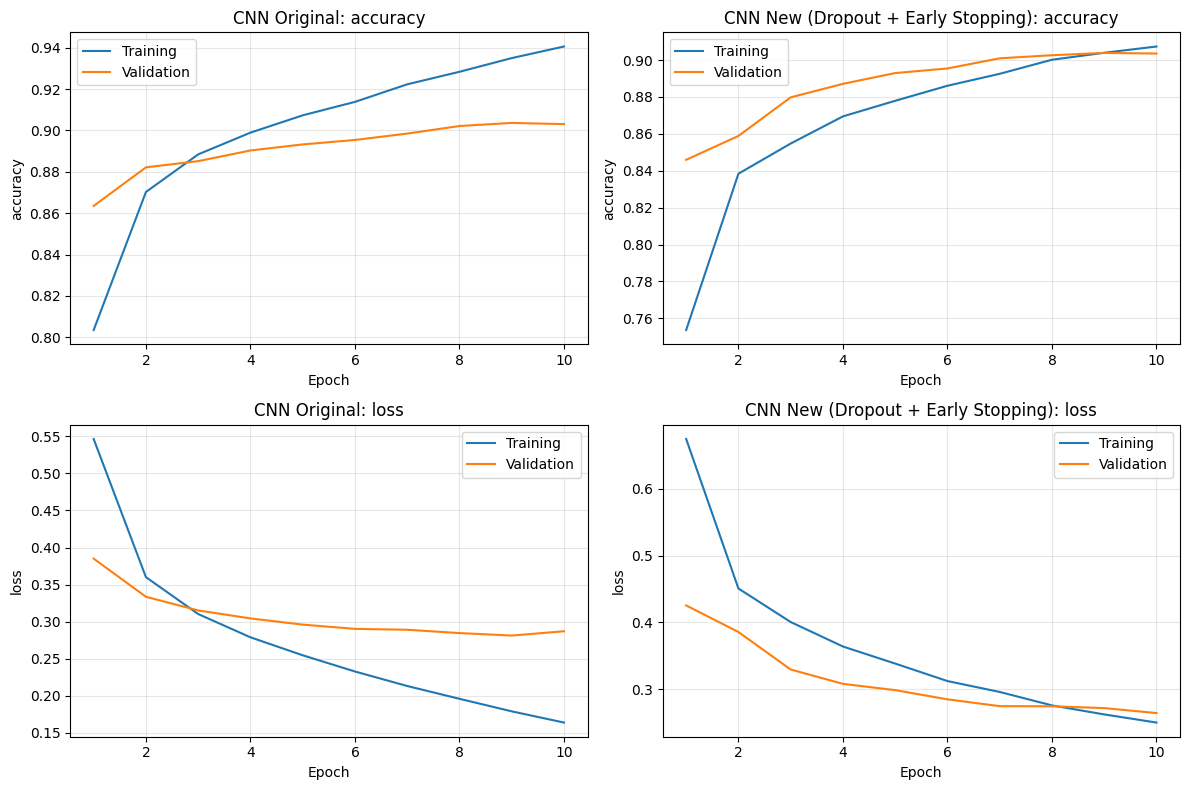

In [43]:
# กราฟ Loss ของโมเดลเดิมที่เลือกและโมเดลใหม่
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name, history in zip(axes, ["Baseline", "New"], [baseline_history, history_new_model]):
    epochs = range(1, len(history.history["loss"]) + 1)
    ax.plot(epochs, history.history["loss"], label="Training Loss")
    ax.plot(epochs, history.history["val_loss"], label="Validation Loss")
    ax.set(title=name, xlabel="Epoch", ylabel="Loss")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 16. ประเมินน้ำหนักปัจจุบัน และเลือกโมเดลสุดท้ายก่อน Test
`evaluate()` วัดผลโดยไม่ปรับน้ำหนัก ประเมินใหม่เพื่อให้คะแนนตรงกับน้ำหนักที่คืนมาจาก Early Stopping ผล Training ในตารางเป็นโหมดประเมิน (ไม่เปิด Dropout) จึงอาจต่างจาก History

เลือกคะแนน Validation สูงสุดจากทั้งสามตัว ถ้าเท่ากัน เลือก โมเดลเดิมที่เลือก ก่อน แล้วจึงตัวอื่นตามลำดับที่กำหนด


In [44]:
candidates = {
    "DNN Original": (dnn_original, x_train, x_val, x_test),
    "CNN Original": (cnn_original, x_train_cnn, x_val_cnn, x_test_cnn),
    new_model_name: (
        new_model,
        x_train_selected,
        x_val_selected,
        x_test_selected
    )
}

results = {}

for name, (model, xtr, xv, xt) in candidates.items():
    train_loss, train_acc = model.evaluate(
        xtr, y_train, verbose=0
    )
    val_loss, val_acc = model.evaluate(
        xv, y_val, verbose=0
    )

    results[name] = {
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    }

selection_order = [selected_original_name, "DNN Original" if use_cnn else "CNN Original", new_model_name]
best_name = max(
    selection_order,
    key=lambda name: results[name]["val_acc"]
)

print("Final model selected by validation:", best_name)
validation_table = pd.DataFrame(results).T
validation_table.index.name = "Model"
display(validation_table.round(4))
original_result = results[selected_original_name]
new_result = results[new_model_name]
print(f"New model minus original model validation accuracy: {(new_result['val_acc']-original_result['val_acc'])*100:+.3f} percentage points")
print(f"New model minus original model validation loss: {new_result['val_loss']-original_result['val_loss']:+.4f}")
print("Positive accuracy difference is better; negative loss difference is better.")
final_model = candidates[best_name][0]


Final model selected by validation: CNN New (Dropout + Early Stopping)


,train_loss,train_acc,val_loss,val_acc
Model,,,,
DNN Original,0.2572,0.9027,0.347,0.8792
CNN Original,0.1759,0.9320,0.287,0.9031
CNN New (Dropout + Early Stopping),0.2119,0.9214,0.272,0.9038


New model minus original model validation accuracy: +0.075 percentage points
New model minus original model validation loss: -0.0150
Positive accuracy difference is better; negative loss difference is better.


## 17. ประเมิน Test ในรอบสุดท้าย
เมื่อเลือกโมเดลแล้ว จึงประเมินทุกโมเดลที่ต้องรายงาน ห้ามใช้คะแนนนี้กลับไปปรับโมเดล โมเดลเดิมที่เลือก คือ DNN หรือ CNN ตัวเดิมจึงไม่ต้องประเมินซ้ำในชื่อใหม่ ตารางใช้ Accuracy เป็นสัดส่วน และแสดงผลโมเดลสุดท้ายเป็นเปอร์เซ็นต์เพิ่มเติม


In [45]:
for name, (model, xtr, xv, xt) in candidates.items():
    test_loss, test_acc = model.evaluate(
        xt, y_test, verbose=0
    )

    results[name]["test_loss"] = test_loss
    results[name]["test_acc"] = test_acc

    print(
        f"{name}: "
        f"Train Acc={results[name]['train_acc']:.4f}, "
        f"Val Acc={results[name]['val_acc']:.4f}, "
        f"Test Acc={test_acc:.4f}, "
        f"Test Loss={test_loss:.4f}"
    )
results_table = pd.DataFrame(results).T
results_table.index.name = "Model"
display(results_table[["train_acc", "val_acc", "test_acc", "train_loss", "val_loss", "test_loss"]].round(4))
print(f"Final selected model: {best_name}; test accuracy = {results[best_name]['test_acc']:.2%}")
print("โมเดลเดิมที่เลือก เทียบกับ โมเดลใหม่:")
display(results_table.loc[[selected_original_name, new_model_name]].round(4))


DNN Original: Train Acc=0.9027, Val Acc=0.8792, Test Acc=0.8715, Test Loss=0.3743
CNN Original: Train Acc=0.9320, Val Acc=0.9031, Test Acc=0.8908, Test Loss=0.3053
CNN New (Dropout + Early Stopping): Train Acc=0.9214, Val Acc=0.9038, Test Acc=0.8941, Test Loss=0.2982


,train_acc,val_acc,test_acc,train_loss,val_loss,test_loss
Model,,,,,,
DNN Original,0.9027,0.8792,0.8715,0.2572,0.347,0.3743
CNN Original,0.9320,0.9031,0.8908,0.1759,0.287,0.3053
CNN New (Dropout + Early Stopping),0.9214,0.9038,0.8941,0.2119,0.272,0.2982


Final selected model: CNN New (Dropout + Early Stopping); test accuracy = 89.41%
โมเดลเดิมที่เลือก เทียบกับ โมเดลใหม่:


,train_loss,train_acc,val_loss,val_acc,test_loss,test_acc
Model,,,,,,
CNN Original,0.1759,0.9320,0.287,0.9031,0.3053,0.8908
CNN New (Dropout + Early Stopping),0.2119,0.9214,0.272,0.9038,0.2982,0.8941


## 18. ดูว่า DNN และ CNN สับสนคลาสไหน
`predict()` ให้คะแนน 10 คลาสต่อภาพ `argmax(axis=1)` เลือกเลขคลาสที่คะแนนสูงที่สุดในแต่ละแถว

Confusion Matrix: แถว = คำตอบจริง คอลัมน์ = คำทำนาย แนวทแยง = ถูก นอกแนวทแยง = ผิด เช่น แถว Shirt คอลัมน์ T-shirt/top หมายถึง Shirt ถูกทำนายเป็น T-shirt/top


DNN Original: probabilities shape=(10000, 10), predictions shape=(10000,)
Correct=8715, Incorrect=1285
CNN Original: probabilities shape=(10000, 10), predictions shape=(10000,)
Correct=8908, Incorrect=1092


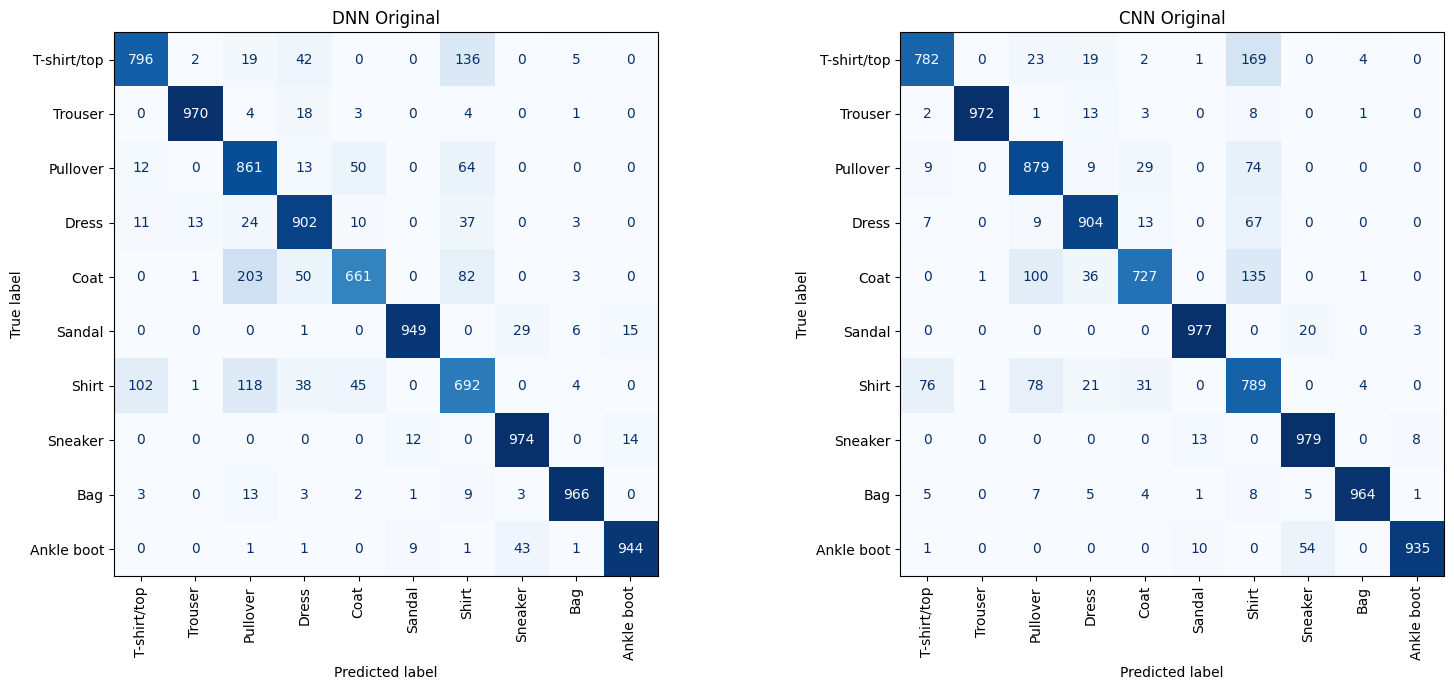

In [46]:
predictions = {}
probabilities_by_model = {}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, name in zip(axes, ["DNN Original", "CNN Original"]):
    model, _, _, xt = candidates[name]

    probabilities = model.predict(xt, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    predictions[name] = y_pred
    probabilities_by_model[name] = probabilities
    print(f"{name}: probabilities shape={probabilities.shape}, predictions shape={y_pred.shape}")
    print(f"Correct={np.sum(y_pred == y_test)}, Incorrect={np.sum(y_pred != y_test)}")

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=np.arange(10),
        display_labels=class_names,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [47]:
# ตัวอย่างหนึ่งภาพ เพื่อเชื่อมคะแนน -> เลขคลาส -> ชื่อคลาส
sample_index = 0
for name in ["DNN Original", "CNN Original"]:
    print(f"{name}, image {sample_index}, true class: {class_names[y_test[sample_index]]}")
    display(pd.DataFrame({"Class": class_names, "Score": probabilities_by_model[name][sample_index]}).round(4))
    print("Predicted class:", class_names[predictions[name][sample_index]])


DNN Original, image 0, true class: Ankle boot


,Class,Score
0,T-shirt/top,0.0000
1,Trouser,0.0000
2,Pullover,0.0000
3,Dress,0.0000
4,Coat,0.0000
5,Sandal,0.0018
6,Shirt,0.0001
7,Sneaker,0.0392
8,Bag,0.0000
9,Ankle boot,0.9588


Predicted class: Ankle boot
CNN Original, image 0, true class: Ankle boot


,Class,Score
0,T-shirt/top,0.000
1,Trouser,0.000
2,Pullover,0.000
3,Dress,0.000
4,Coat,0.000
5,Sandal,0.000
6,Shirt,0.000
7,Sneaker,0.001
8,Bag,0.000
9,Ankle boot,0.999


Predicted class: Ankle boot


## 19. แสดงภาพถูก 5 ภาพและผิด 5 ภาพ
เลือก DNN หรือ CNN ที่ Test Accuracy สูงกว่าเพื่อแสดงตัวอย่างตามขั้นตอนงานเดิม การเลือกส่วนนี้ไม่เปลี่ยนโมเดลสุดท้ายที่เลือกด้วย Validation

`np.where()` หาตำแหน่งที่ทำนายตรง/ไม่ตรงกับคำตอบจริง แล้ว `[:5]` เลือกห้าภาพแรก ตัวอย่างเหล่านี้ไม่ได้แทนความผิดพลาดทั้งหมด


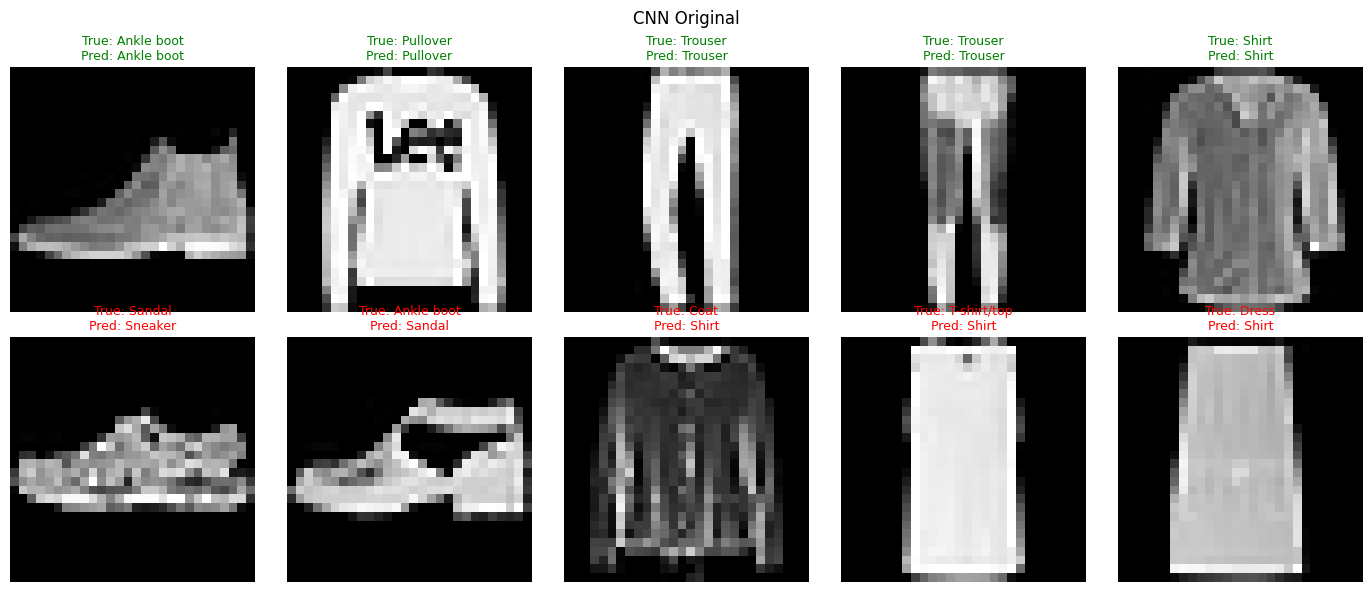

In [49]:
example_name = max(
    ["DNN Original", "CNN Original"],
    key=lambda name: results[name]["test_acc"]
)

y_pred = predictions[example_name]

correct_indices = np.where(y_pred == y_test)[0][:5]
wrong_indices = np.where(y_pred != y_test)[0][:5]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for row, indices in enumerate(
    [correct_indices, wrong_indices]
):
    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(indices):
            continue
        idx = indices[col]

        ax.imshow(x_test[idx], cmap="gray")
        ax.set_title(
            f"True: {class_names[y_test[idx]]}\n"
            f"Pred: {class_names[y_pred[idx]]}",
            color="green" if row == 0 else "red",
            fontsize=9
        )
plt.suptitle(example_name)
plt.tight_layout()
plt.show()


## 20. เขียนอภิปรายจากผลจริงหลังรัน

| คำถาม | หลักฐานที่จะอ้าง |
|---|---|
| ทำไมเลือก โมเดลเดิมที่เลือก ตัวนี้? | ตาราง Validation ข้อ 12 |
| ปรับอะไรและเพราะอะไร? | กราฟข้อ 11 และสมมติฐานข้อ 13 |
| โมเดลใหม่ (เพิ่ม Dropout + Early Stopping) ดีขึ้นหรือไม่? | ผลต่าง Validation และตารางข้อ 16 |
| ลด Overfitting หรือไม่? | แนวโน้ม Training/Validation Loss ข้อ 15 |
| โมเดลสุดท้ายคืออะไรและ Test ได้เท่าไร? | การเลือกข้อ 16 และผลข้อ 17 |
| โมเดลสับสนอะไร? | Confusion Matrix ข้อ 18 |
| ภาพที่ผิดมีลักษณะอย่างไร? | ตัวอย่างภาพข้อ 19 |

เติมข้อสรุปของตนเองหลังรัน: **[โมเดลเดิมที่เลือก และเหตุผล] → [เทคนิคที่ทดลอง] → [ผลต่างที่ได้จริง] → [โมเดลสุดท้ายและ Test] → [ข้อผิดพลาดที่ยังพบ]**

อย่าสรุปว่าเทคนิคช่วยแน่นอนจากชื่อ โมเดลใหม่ (เพิ่ม Dropout + Early Stopping) หรือจาก Training Accuracy อย่างเดียว ผลการรันครั้งเดียวอาจมีความแปรปรวนจากการเริ่มน้ำหนักและการสุ่ม และภาพ Fashion-MNIST ขนาดเล็กสีเทายังไม่ใช่หลักฐานว่าใช้กับภาพสินค้าจริงได้ทันที
